# 08 · Decisão de negócio: pontos de corte e custo assimétrico

Um modelo só gera valor quando vira **política de decisão**. Este notebook responde:

- **Parte A (pergunta 6):** qual ponto de corte do **score atual** maximiza o lucro, sabendo que a
  empresa ganha **10%** de cada pagamento legítimo aprovado e perde **100%** de cada fraude aprovada?
- **Parte B:** quanto o **novo modelo** vale em R$ sob a mesma regra?
- **Parte C (pergunta 5):** o que muda se **uma fraude custar 10x mais** que um bloqueio indevido?

**Convenção:** aprova-se quando o score < corte; rejeita-se quando score ≥ corte. Rejeitar não gera
receita nem perda (o atrito com o cliente rejeitado é discutido na resposta 5).

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from fraude.inferencia import ModeloFraude
from fraude.features import ConstrutorFeatures

MARGEM, PERDA = cfg.MARGEM_APROVACAO, cfg.PERDA_FRAUDE
fmt_rs = lambda v: f"R$ {v:,.0f}".replace(",", ".")

In [2]:
base = dados.carregar_base()
oof = pd.read_parquet(cfg.ARQUIVO_PRED_OOF)      # período dev (22/03–10/04): predições out-of-fold
teste = pd.read_parquet(cfg.ARQUIVO_PRED_TESTE)  # período de teste (11/04–21/04)
print(f"base {len(base):,} | dev OOF {len(oof):,} | teste {len(teste):,}")

base 150,000 | dev OOF 58,735 | teste 41,534


---
# Parte A — Ponto de corte ótimo do score atual (pergunta 6)

## A.1 A matemática da decisão
Para um pagamento de valor $m$ com probabilidade de fraude $p$:

$$\text{E[lucro | aprovar]} = 0{,}10 \cdot m \cdot (1-p) - 1{,}00 \cdot m \cdot p \qquad \text{E[lucro | rejeitar]} = 0$$

Vale aprovar quando $0{,}10(1-p) > p \iff p < \dfrac{0{,}10}{1{,}10} = \dfrac{1}{11} \approx 9{,}1\%$.

Duas consequências:
1. Com um modelo **calibrado**, o corte ótimo é **p = 1/11, independentemente do valor** (o valor
   multiplica os dois lados).
2. O score atual **não é uma probabilidade** (é um percentil, nb 02). Para ele, a regra equivalente é:
   rejeitar as faixas de score em que a **fração do valor (R$) que é fraude** passa de 1/11. Na prática,
   encontramos o corte por **busca exaustiva** dos 102 cortes possíveis.

Como o score atual não foi treinado neste projeto, usamos a **base completa** (150 mil transações) para
estimar o corte com a maior precisão possível, e checamos a estabilidade por período.

In [3]:
curva = metricas.curva_lucro(base["fraude"], base["score"], base["monto"], cortes=np.arange(0, 102))
aprovar_tudo = metricas.resultado_transacao(base["fraude"], base["monto"]).sum()
otimo = curva.loc[curva["lucro"].idxmax()]
c_otimo = int(otimo["corte"])
print(f"Corte ótimo: aprovar score < {c_otimo} (score ≤ {c_otimo - 1}) e rejeitar score ≥ {c_otimo}")
print(f"Lucro ótimo: {fmt_rs(otimo['lucro'])}  vs aprovar tudo: {fmt_rs(aprovar_tudo)}  "
      f"({otimo['lucro'] / aprovar_tudo:.1f}x)")

Corte ótimo: aprovar score < 76 (score ≤ 75) e rejeitar score ≥ 76
Lucro ótimo: R$ 264.929  vs aprovar tudo: R$ 50.849  (5.2x)


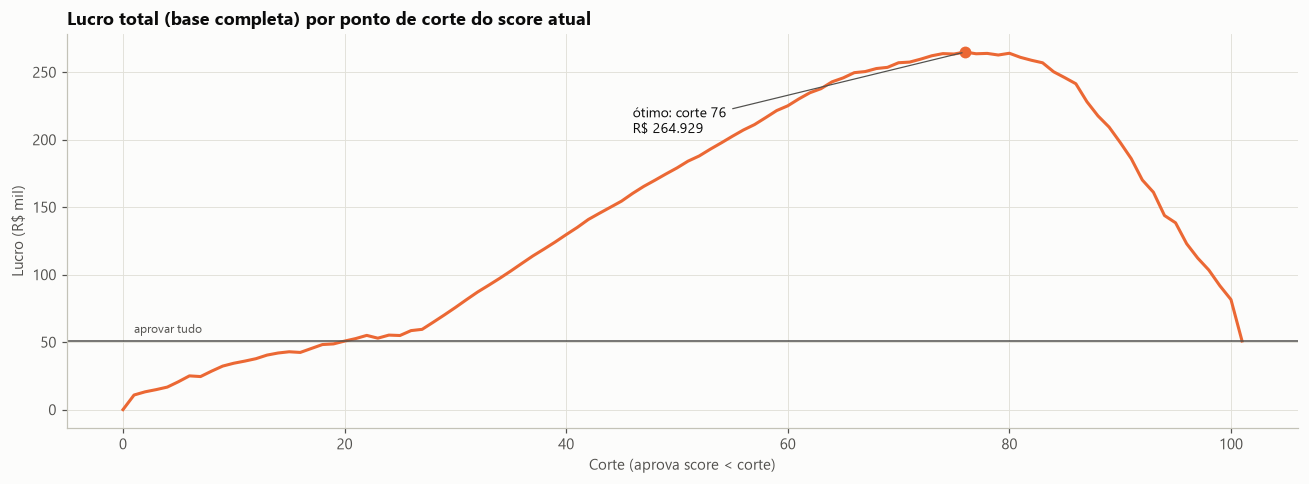

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(curva["corte"], curva["lucro"] / 1e3, color=gr.LARANJA)
ax.axhline(aprovar_tudo / 1e3, color=gr.TINTA_2, lw=1)
ax.text(1, aprovar_tudo / 1e3 + 6, "aprovar tudo", fontsize=8, color=gr.TINTA_2)
ax.scatter([c_otimo], [otimo["lucro"] / 1e3], color=gr.LARANJA, s=60, zorder=3)
ax.annotate(f"ótimo: corte {c_otimo}\n{fmt_rs(otimo['lucro'])}", xy=(c_otimo, otimo["lucro"] / 1e3),
            xytext=(c_otimo - 30, otimo["lucro"] / 1e3 - 60), fontsize=9,
            arrowprops=dict(arrowstyle="-", color=gr.TINTA_2, lw=0.8))
ax.set(title="Lucro total (base completa) por ponto de corte do score atual",
       xlabel="Corte (aprova score < corte)", ylabel="Lucro (R$ mil)")
plt.tight_layout()

In [5]:
vizinhanca = curva.set_index("corte").loc[66:86].copy()
vizinhanca["% do lucro ótimo"] = vizinhanca["lucro"] / otimo["lucro"]
vizinhanca.style.format({"lucro": lambda v: fmt_rs(v), "taxa_aprovacao": "{:.1%}", "fraudes_bloqueadas_pct": "{:.1%}",
                         "valor_fraude_bloqueado_pct": "{:.1%}", "legitimas_bloqueadas_pct": "{:.1%}",
                         "% do lucro ótimo": "{:.1%}"}).highlight_max(subset=["lucro"], color="#cde2fb")

,lucro,taxa_aprovacao,fraudes_bloqueadas_pct,valor_fraude_bloqueado_pct,legitimas_bloqueadas_pct,% do lucro ótimo
corte,,,,,,
66,R$ 249.650,67.5%,72.2%,78.1%,30.4%,94.2%
67,R$ 250.490,68.5%,71.5%,77.2%,29.4%,94.5%
68,R$ 252.715,69.6%,70.7%,76.5%,28.3%,95.4%
69,R$ 253.591,70.5%,69.8%,75.6%,27.3%,95.7%
70,R$ 257.006,71.5%,69.1%,75.1%,26.3%,97.0%
71,R$ 257.492,72.5%,68.3%,74.0%,25.3%,97.2%
72,R$ 259.679,73.5%,67.5%,73.3%,24.3%,98.0%
73,R$ 262.179,74.5%,66.4%,72.6%,23.3%,99.0%
74,R$ 263.766,75.5%,65.2%,71.5%,22.3%,99.6%


## A.2 Por que exatamente esse corte? A regra de 1/11 aplicada ao score

Pela matemática acima, vale rejeitar um valor de score quando a **fração do valor transacionado que é
fraude** passa de 1/11 ≈ 9,1%. O gráfico mostra essa fração para cada score. Ela é ruidosa por score
individual, mas cruza a linha de 9,1% justamente na região do corte ótimo.

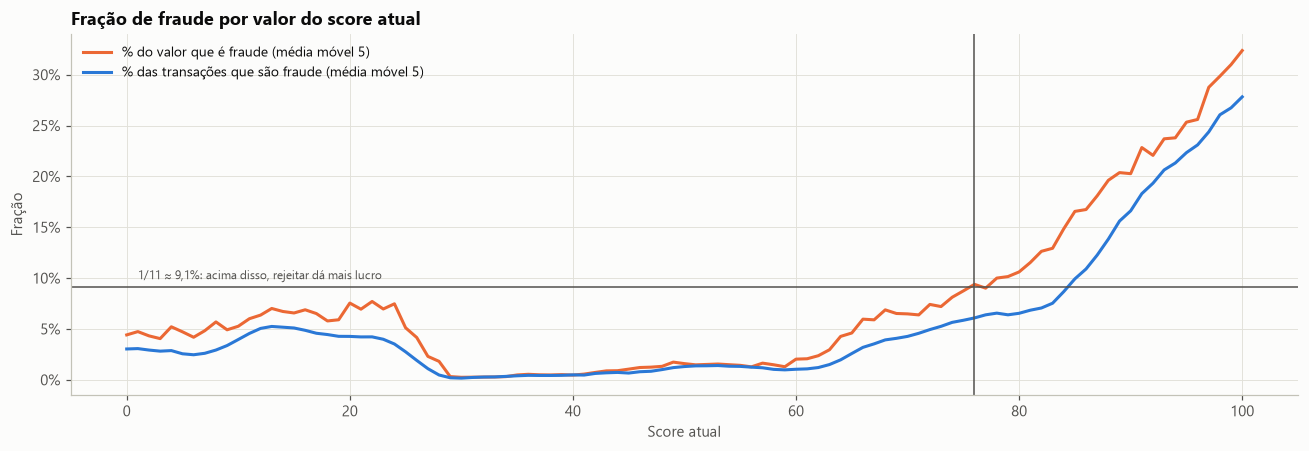

In [6]:
por_score = base.groupby("score").apply(lambda g: pd.Series({
    "fracao_valor_fraude": (g["monto"] * g["fraude"]).sum() / g["monto"].sum(),
    "taxa_fraude_qtd": g["fraude"].mean()}))
suav = por_score.rolling(5, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(suav.index, suav["fracao_valor_fraude"], color=gr.LARANJA, label="% do valor que é fraude (média móvel 5)")
ax.plot(suav.index, suav["taxa_fraude_qtd"], color=gr.AZUL, label="% das transações que são fraude (média móvel 5)")
ax.axhline(1 / 11, color=gr.TINTA_2, lw=1)
ax.text(1, 1 / 11 + 0.008, "1/11 ≈ 9,1%: acima disso, rejeitar dá mais lucro", fontsize=8, color=gr.TINTA_2)
ax.axvline(c_otimo, color=gr.TINTA_2, lw=1)
ax.set(title="Fração de fraude por valor do score atual", xlabel="Score atual", ylabel="Fração")
gr.formatar_pct(ax)
ax.legend(loc="upper left")
plt.tight_layout()

Repare que a fração **em valor** (laranja) fica acima da fração **em quantidade** (azul): fraudes têm
ticket maior. Por isso o corte ótimo (~76) fica **abaixo** do ponto em que a taxa de fraude em
quantidade atinge 9,1%. Otimizar por quantidade, ignorando o valor, levaria a um corte alto demais e
deixaria passar fraudes caras.

## A.3 Robustez do corte

,corte_otimo,lucro_no_otimo,lucro_com_corte_76,eficiencia
particao,,,,
treino,76,R$ 135.875,R$ 135.875,100.0%
validacao,73,R$ 50.582,R$ 48.800,96.5%
teste,77,R$ 80.807,R$ 80.253,99.3%


IC 90% do corte ótimo: [73, 81] | moda: 76


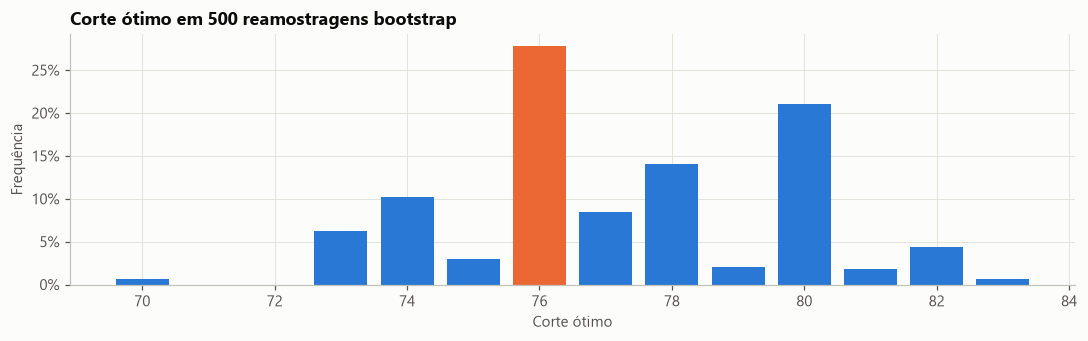

In [7]:
# (1) Corte ótimo estimado separadamente em cada partição
por_part = []
for part, g in base.groupby("particao", sort=False):
    c = metricas.curva_lucro(g["fraude"], g["score"], g["monto"], cortes=np.arange(0, 102))
    o = c.loc[c["lucro"].idxmax()]
    lucro_76 = c.set_index("corte").loc[c_otimo, "lucro"]
    por_part.append({"particao": part, "corte_otimo": int(o["corte"]), "lucro_no_otimo": o["lucro"],
                     f"lucro_com_corte_{c_otimo}": lucro_76, "eficiencia": lucro_76 / o["lucro"]})
display(pd.DataFrame(por_part).set_index("particao").style.format(
    {"lucro_no_otimo": fmt_rs, f"lucro_com_corte_{c_otimo}": fmt_rs, "eficiencia": "{:.1%}"}))

# (2) Bootstrap: distribuição do corte ótimo sob reamostragem das transações
rng = np.random.default_rng(cfg.SEED)
res = metricas.resultado_transacao(base["fraude"], base["monto"])
sc = base["score"].to_numpy()
cortes_boot = []
for _ in range(500):
    idx = rng.integers(0, len(base), len(base))
    lucro_por_score = np.bincount(sc[idx], weights=res[idx], minlength=101)
    cortes_boot.append(int(np.argmax(np.concatenate([[0], np.cumsum(lucro_por_score)]))))
boot = pd.Series(cortes_boot)

fig, ax = plt.subplots(figsize=(10, 3.2))
vc = boot.value_counts(normalize=True).sort_index()
ax.bar(vc.index, vc.values, color=np.where(vc.index == c_otimo, gr.LARANJA, gr.AZUL), width=0.8)
ax.set(title="Corte ótimo em 500 reamostragens bootstrap", xlabel="Corte ótimo", ylabel="Frequência")
gr.formatar_pct(ax)
plt.tight_layout()
print(f"IC 90% do corte ótimo: [{boot.quantile(0.05):.0f}, {boot.quantile(0.95):.0f}] | moda: {boot.mode()[0]}")

**Resposta da pergunta 6:** o corte que maximiza o lucro é **76**. **Aprovar pagamentos com score ≤ 75
e rejeitar os com score ≥ 76.**

- O lucro sobe de ~R$ 51 mil (aprovar tudo) para **~R$ 265 mil** na base, **~5,2x mais**, rejeitando
  ~22% dos pagamentos, que bloqueiam 63% das fraudes e ~69% do valor fraudado.
- A curva é **achatada no topo**: cortes entre ~73 e ~80 entregam praticamente o mesmo lucro. O
  bootstrap confirma que o ótimo oscila nessa faixa. Isso é bom, porque pequenas mudanças de
  população não destroem o resultado.
- O ótimo é **estável entre períodos** (76 no treino, 73 na validação, 77 no teste), e usar 76 em
  todos captura de 96,5% a 100% do lucro máximo de cada período. Mesmo assim, como a taxa de fraude e o
  próprio score mudaram no tempo (nb 01/02), o corte deve ser **revisado periodicamente** com dados
  recentes.
- **Limitação estrutural:** nenhum corte resolve a **zona cega** (score 0–25), cujas fraudes são sempre
  aprovadas. Só um modelo melhor resolve isso (Parte B).

---
# Parte B — Quanto vale o novo modelo em R$?

Para uma comparação justa, os **dois** modelos têm o corte escolhido **no mesmo período passado**
(dev: 22/03–10/04, predições out-of-fold) e são aplicados **no teste** (11/04–21/04), como aconteceria
em produção.

Para o novo modelo, comparamos dois limiares:
- **teórico:** p = 1/11 (vale se o modelo estiver calibrado);
- **empírico:** o que maximizou o lucro no dev.

Escolhidos no dev -> score atual: corte 74 | novo modelo: p ≥ 0.0877 (teórico 1/11 = 0.0909)


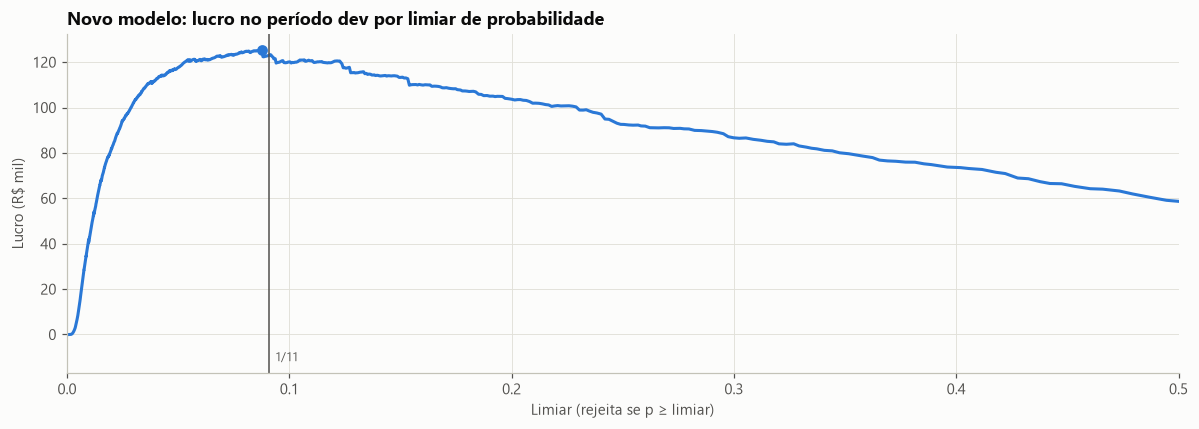

In [8]:
def melhor_corte(y, s, valor, cortes):
    c = metricas.curva_lucro(y, s, valor, cortes=cortes)
    return c.loc[c["lucro"].idxmax(), "corte"], c

grade_p = np.unique(np.concatenate([np.quantile(oof["p_modelo"], np.linspace(0, 1, 2001)), [1 / 11]]))
lim_novo_dev, curva_novo_dev = melhor_corte(oof["fraude"], oof["p_modelo"], oof["monto"], grade_p)
c_atual_dev, curva_atual_dev = melhor_corte(oof["fraude"], oof["score"], oof["monto"], np.arange(0, 102))
print(f"Escolhidos no dev -> score atual: corte {c_atual_dev:.0f} | novo modelo: p ≥ {lim_novo_dev:.4f} "
      f"(teórico 1/11 = {1/11:.4f})")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(curva_novo_dev["corte"], curva_novo_dev["lucro"] / 1e3, color=gr.AZUL)
ax.axvline(1 / 11, color=gr.TINTA_2, lw=1)
ax.text(1 / 11, ax.get_ylim()[0] + 5, "  1/11", fontsize=8, color=gr.TINTA_2)
ax.scatter([lim_novo_dev], [curva_novo_dev["lucro"].max() / 1e3], color=gr.AZUL, s=50, zorder=3)
ax.set(title="Novo modelo: lucro no período dev por limiar de probabilidade", xlabel="Limiar (rejeita se p ≥ limiar)",
       ylabel="Lucro (R$ mil)", xlim=(0, 0.5))
plt.tight_layout()

In [9]:
def politica(nome, y, s, valor, corte):
    aprova = np.asarray(s) < corte
    y, valor = np.asarray(y), np.asarray(valor)
    r = metricas.resultado_transacao(y, valor)
    return {"política": nome, "corte": corte, "lucro": r[aprova].sum(),
            "taxa_aprovacao": aprova.mean(),
            "fraudes_bloqueadas": (~aprova & (y == 1)).sum() / (y == 1).sum(),
            "valor_fraude_bloqueado": (valor * y)[~aprova].sum() / (valor * y).sum(),
            "legitimas_bloqueadas": (~aprova & (y == 0)).sum() / (y == 0).sum()}

yt, vt = teste["fraude"], teste["monto"]
pols = pd.DataFrame([
    politica("Aprovar tudo", yt, np.zeros(len(teste)), vt, 1),
    politica(f"Score atual (corte {c_atual_dev:.0f}, escolhido no dev)", yt, teste["score"], vt, c_atual_dev),
    politica(f"Score atual (corte {c_otimo}, base completa)", yt, teste["score"], vt, c_otimo),
    politica("Novo modelo (limiar teórico 1/11)", yt, teste["p_modelo"], vt, 1 / 11),
    politica("Novo modelo (limiar escolhido no dev)", yt, teste["p_modelo"], vt, lim_novo_dev),
]).set_index("política")
ref = pols.loc[f"Score atual (corte {c_atual_dev:.0f}, escolhido no dev)", "lucro"]
pols["Δ lucro vs score atual"] = pols["lucro"] - ref
pols["Δ %"] = pols["lucro"] / ref - 1
pols.style.format({"corte": "{:.4g}", "lucro": fmt_rs, "Δ lucro vs score atual": fmt_rs, "Δ %": "{:+.1%}", "taxa_aprovacao": "{:.1%}",
                   "fraudes_bloqueadas": "{:.1%}", "valor_fraude_bloqueado": "{:.1%}", "legitimas_bloqueadas": "{:.1%}"})

,corte,lucro,taxa_aprovacao,fraudes_bloqueadas,valor_fraude_bloqueado,legitimas_bloqueadas,Δ lucro vs score atual,Δ %
política,,,,,,,,
Aprovar tudo,1,R$ 22.660,100.0%,0.0%,0.0%,0.0%,R$ -56.410,-71.3%
"Score atual (corte 74, escolhido no dev)",74,R$ 79.070,81.2%,61.7%,65.7%,16.8%,R$ 0,+0.0%
"Score atual (corte 76, base completa)",76,R$ 80.253,83.1%,60.2%,64.4%,14.9%,R$ 1.184,+1.5%
Novo modelo (limiar teórico 1/11),0.09091,R$ 96.229,84.6%,65.1%,77.9%,13.1%,R$ 17.160,+21.7%
Novo modelo (limiar escolhido no dev),0.08765,R$ 95.803,83.9%,66.2%,78.5%,13.7%,R$ 16.733,+21.2%


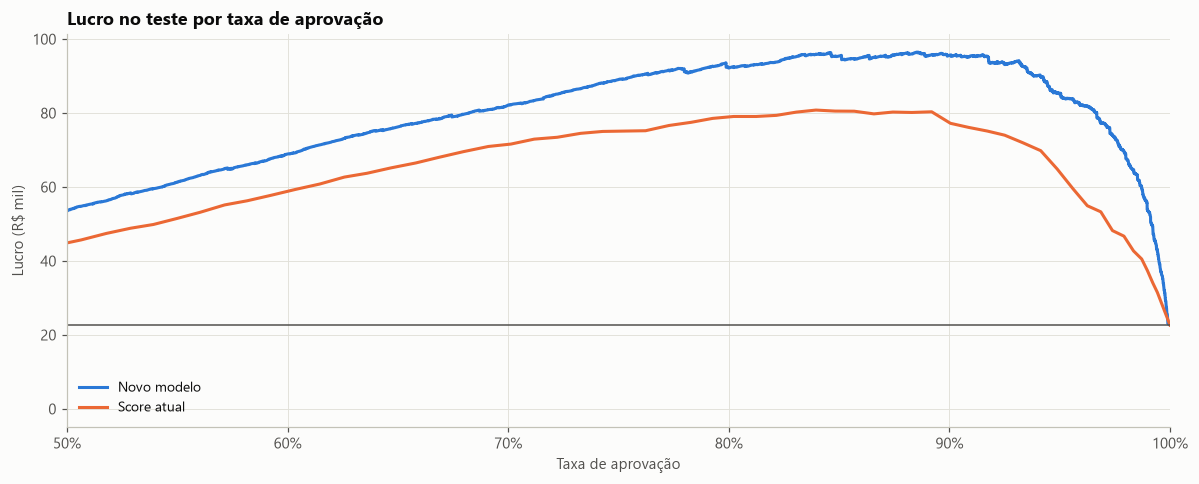

In [10]:
# Curvas de lucro no teste em função da taxa de aprovação: compara os modelos na mesma "régua"
fig, ax = plt.subplots(figsize=(11, 4.5))
for nome, s, cor in [("Novo modelo", teste["p_modelo"], gr.AZUL), ("Score atual", teste["score"], gr.LARANJA)]:
    c = metricas.curva_lucro(yt, s, vt)
    ax.plot(c["taxa_aprovacao"], c["lucro"] / 1e3, color=cor, label=nome)
ax.axhline(pols.loc["Aprovar tudo", "lucro"] / 1e3, color=gr.TINTA_2, lw=1)
ax.set(title="Lucro no teste por taxa de aprovação", xlabel="Taxa de aprovação", ylabel="Lucro (R$ mil)", xlim=(0.5, 1.0))
gr.formatar_pct(ax, "x")
ax.legend(loc="lower left")
plt.tight_layout()

**Leitura:**
- Com os cortes escolhidos no passado (dev) e aplicados no futuro (teste), o novo modelo gera
  **~R$ 95,8 mil contra ~R$ 79,1 mil do score atual: +R$ 16,7 mil (+21%)** em 11 dias de amostra.
  Contra aprovar tudo (~R$ 22,7 mil), o ganho é de ~4x.
- O novo modelo **aprova mais pagamentos** (83,9% contra 81,2%), **bloqueia menos clientes bons**
  (13,7% contra 16,8% das legítimas) e **ainda barra mais valor fraudado** (78,5% contra 65,7%). Ele ganha
  nos dois lados do trade-off: mais receita e menos perda.
- Em **qualquer taxa de aprovação** entre 50% e 100%, a curva do novo modelo domina a do score atual. O
  topo da curva azul também é **largo** (lucro quase constante entre ~84% e ~92% de aprovação), então a
  política é robusta a pequenos desvios do limiar.
- O limiar escolhido no dev (**p ≥ 0,088**) é praticamente o limiar teórico **1/11 ≈ 0,091**, e os dois
  dão o mesmo lucro no teste. Isso confirma que a calibração está fazendo seu papel. Salvamos no
  artefato o limiar escolhido empiricamente no passado.

In [11]:
# Persistimos a política escolhida no artefato de produção (usada pela API e pelo nb 09)
artefato = ModeloFraude.carregar(cfg.ARQUIVO_MODELO)
artefato.limiar = float(lim_novo_dev)
artefato.metadados["politica"] = {"regra": "rejeitar se probabilidade >= limiar", "limiar": float(lim_novo_dev),
                                  "criterio": "lucro máximo no período dev (margem 10%, perda 100%)",
                                  "limiar_teorico": 1 / 11}
artefato.salvar(cfg.ARQUIVO_MODELO)
print("Limiar salvo no artefato:", round(artefato.limiar, 4))

Limiar salvo no artefato: 0.0877


---
# Parte C — E se uma fraude custar 10x mais que um bloqueio indevido? (pergunta 5)

Agora o custo é por **quantidade**: cada fraude aprovada (FN) custa 10 e cada legítima bloqueada (FP)
custa 1. O que muda:

### C.1 O limiar de decisão
Minimizar o custo esperado leva a rejeitar quando

$$p \cdot C_{FN} > (1-p) \cdot C_{FP} \iff p > \frac{C_{FP}}{C_{FP} + C_{FN}} = \frac{1}{11} \approx 0{,}091$$

e **não 0,5**, o limiar padrão de `predict()`. Curiosamente, chegamos ao **mesmo 1/11** da pergunta 6:
lá a razão perda/margem também era 10 (100% vs 10%). A diferença é que na pergunta 5 o custo é por
transação e, na 6, proporcional ao valor.

In [12]:
def custo_por_limiar(y, p, limiares):
    return pd.Series([metricas.custo_esperado(y, p >= l) for l in limiares], index=limiares)

lims = np.round(np.linspace(0.01, 0.6, 119), 4)
custo_teste = custo_por_limiar(yt, teste["p_modelo"].to_numpy(), lims)
custo_dev = custo_por_limiar(oof["fraude"], oof["p_modelo"].to_numpy(), lims)
lim_custo_dev = custo_dev.idxmin()

tab_custo = pd.DataFrame([
    {"limiar": "0,5 (padrão do predict)", "valor": 0.5},
    {"limiar": "1/11 (teórico)", "valor": 1 / 11},
    {"limiar": f"{lim_custo_dev:.3f} (mín. custo no dev)", "valor": lim_custo_dev},
]).set_index("limiar")
for col, (y_, p_) in {"teste": (yt, teste["p_modelo"])}.items():
    tab_custo["custo no teste"] = [metricas.custo_esperado(y_, p_ >= v) for v in tab_custo["valor"]]
    tab_custo["fraudes aprovadas (FN)"] = [int(((p_ < v) & (y_ == 1)).sum()) for v in tab_custo["valor"]]
    tab_custo["bloqueios indevidos (FP)"] = [int(((p_ >= v) & (y_ == 0)).sum()) for v in tab_custo["valor"]]
custo_aprovar_tudo = metricas.custo_esperado(yt, np.zeros(len(yt), bool))
tab_custo["redução vs aprovar tudo"] = 1 - tab_custo["custo no teste"] / custo_aprovar_tudo
print(f"Custo de aprovar tudo no teste: {custo_aprovar_tudo:,.0f}")
tab_custo.style.format({"valor": "{:.3f}", "custo no teste": "{:,.0f}", "redução vs aprovar tudo": "{:.1%}"})

Custo de aprovar tudo no teste: 18,540


,valor,custo no teste,fraudes aprovadas (FN),bloqueios indevidos (FP),redução vs aprovar tudo
limiar,,,,,
"0,5 (padrão do predict)",0.500,"15,036",1480,236,18.9%
1/11 (teórico),0.091,"11,680",647,5210,37.0%
0.105 (mín. custo no dev),0.105,"11,494",712,4374,38.0%


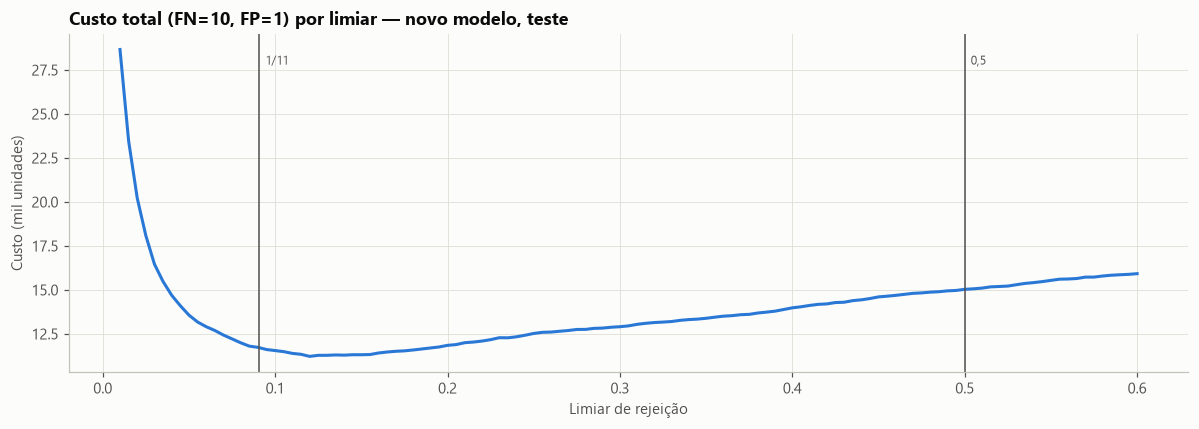

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(custo_teste.index, custo_teste.values / 1e3, color=gr.AZUL, label="custo no teste")
for v, rot in [(0.5, "0,5"), (1 / 11, "1/11")]:
    ax.axvline(v, color=gr.TINTA_2, lw=1)
    ax.text(v, custo_teste.max() / 1e3 * 0.97, f"  {rot}", fontsize=8, color=gr.TINTA_2)
ax.set(title="Custo total (FN=10, FP=1) por limiar — novo modelo, teste", xlabel="Limiar de rejeição",
       ylabel="Custo (mil unidades)")
plt.tight_layout()

### C.2 E se treinarmos já "sabendo" do custo? (*cost-sensitive learning*)
Uma alternativa é embutir o custo no treino, dando **peso 10 às fraudes**. A teoria diz que isso
multiplica as chances previstas por ~10, o que equivale a mover o limiar de 1/11 para ~0,5. Ou seja,
*pesar o treino* e *mover o limiar* devem dar resultados parecidos. Testamos:

In [14]:
%%time
dev = base[base["particao"] != "teste"].reset_index(drop=True)
te = base[base["particao"] == "teste"].reset_index(drop=True)
cf = ConstrutorFeatures()
X_dev = cf.fit_transform(dev, dev["fraude"])
X_te = cf.transform(te)[X_dev.columns]
params = artefato.metadados["hiperparametros"]
pesado = lgb.LGBMClassifier(**params).fit(X_dev, dev["fraude"], sample_weight=np.where(dev["fraude"] == 1, 10.0, 1.0))
p_pesado = pesado.predict_proba(X_te)[:, 1]

comp_cs = pd.DataFrame({
    "PR AUC": [average_precision_score(yt, teste["p_modelo"]), average_precision_score(yt, p_pesado)],
    "ROC AUC": [roc_auc_score(yt, teste["p_modelo"]), roc_auc_score(yt, p_pesado)],
    "limiar usado": [1 / 11, 0.5],
    "custo no teste": [metricas.custo_esperado(yt, teste["p_modelo"] >= 1 / 11), metricas.custo_esperado(yt, p_pesado >= 0.5)],
    "custo mínimo possível (oráculo)": [custo_por_limiar(yt, teste["p_modelo"].to_numpy(), lims).min(),
                                        custo_por_limiar(yt, p_pesado, np.round(np.linspace(0.05, 0.95, 181), 4)).min()],
}, index=["Sem peso + calibração + limiar 1/11", "Peso 10 nas fraudes + limiar 0,5"])
comp_cs.style.format({"PR AUC": "{:.3f}", "ROC AUC": "{:.3f}", "limiar usado": "{:.3f}",
                      "custo no teste": "{:,.0f}", "custo mínimo possível (oráculo)": "{:,.0f}"})

CPU times: total: 26.2 s
Wall time: 21.6 s


,PR AUC,ROC AUC,limiar usado,custo no teste,custo mínimo possível (oráculo)
Sem peso + calibração + limiar 1/11,0.368,0.851,0.091,"11,680","11,224"
"Peso 10 nas fraudes + limiar 0,5",0.365,0.850,0.500,"11,502","11,417"


**Resultados no teste:**
- Trocar o limiar padrão **0,5 por 1/11** reduz o custo total de ~15,0 mil para **~11,7 mil (−22%)**. O
  modelo passa a aprovar 647 fraudes em vez de 1.480, ao preço de mais bloqueios indevidos (5.210 contra
  236). Com fraude custando 10x, essa troca compensa. O limiar de mínimo custo estimado no dev (~0,105)
  fica perto do teórico.
- As duas abordagens (peso 10 + limiar 0,5 vs sem peso + limiar 1/11) chegam a **custos próximos**
  (diferença de ~1,5%), como prevê a teoria. No teste, a versão com peso fica levemente à frente no
  limiar fixo, porque o modelo calibrado superestima o risco neste período (nb 07). Mas a versão sem
  peso tem **melhor ordenação** (PR AUC) e **menor custo mínimo atingível** (oráculo).

Preferimos **treinar sem peso, calibrar e mover o limiar**:
- uma única probabilidade calibrada serve a **qualquer** estrutura de custo. Se o custo mudar de 10x
  para 8x, muda-se só o limiar, sem retreino;
- a probabilidade continua interpretável para monitoramento e para outras áreas (ex.: crédito, pricing
  de risco).

### C.3 O que mais muda com custo 10:1 (resumo para a resposta 5)
1. **Limiar:** de 0,5 para 1/11. O modelo passa a bloquear com bem menos certeza, aceitando mais
   falsos positivos para evitar fraudes.
2. **Métrica de avaliação e de tuning:** custo esperado (ou lucro) em vez de acurácia/F1. Na seleção de
   modelos, priorizar **recall na região de baixo limiar** e PR AUC.
3. **Ponto de corte por segmento/valor:** com custos proporcionais ao valor (pergunta 6), o limiar em
   probabilidade é o mesmo, mas a **ordem de prioridade** dá peso a transações caras. Na prática, pode
   valer limiar diferenciado por segmento (ex.: categorias de alto risco, novos usuários).
4. **Terceira via (revisão manual / autenticação adicional):** com custo de FN tão alto, a zona
   cinzenta (ex.: 5% < p < 20%) pode ir para *step-up authentication* (3DS, biometria) ou fila de
   analistas, em vez de bloqueio seco, reduzindo o custo de FP sem deixar passar fraude.
5. **Atenção ao custo real do FP:** o "1x" do bloqueio indevido subestima efeitos de longo prazo
   (cliente que desiste da plataforma). Vale medir via experimento e revisar a razão de custos.

---
## Conclusões

| Pergunta | Resposta |
|---|---|
| **6. Corte ótimo do score atual** | **Aprovar score ≤ 75 e rejeitar score ≥ 76.** Lucro de ~R$ 265 mil na base contra ~R$ 51 mil aprovando tudo (5x), com platô estável entre ~73 e ~80. |
| **Novo modelo em R$** | Com corte escolhido no passado e aplicado no teste: **+R$ 16,7 mil (+21%)** sobre o score atual, aprovando mais (83,9% vs 81,2%) e bloqueando mais valor fraudado (78,5% vs 65,7%). |
| **5. Fraude custa 10x** | Limiar de 0,5 → **1/11** (−22% de custo no teste), métrica de custo esperado no lugar de acurácia, preferência por calibração + limiar em vez de reponderar o treino, faixa cinzenta para autenticação adicional/revisão. |

➡️ **Próximo passo (09):** o modelo é viável online, rápido e idêntico ao laboratório?